# **Un Análisis Exploratorio de Datos (EDA – Exploratory Data Analysis)**

## EXPLORACION DE ARCHIVO TIPO XLSX




Carlos Francisco Montoya Urzúa

23 de marzo de 2026

Importar librerias

Las más usadas en análisis de datos:

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


2. Cargar los datos
Generalmente desde un archivo CSV.


In [3]:
df = pd.read_csv("ventaCSV.csv")

#Ver primeras filas:
print(df.head())

   id nombre   edad       ciudad  ventas ganancias
0   1    Ana   25.0       Mexico   100.0      "10"
1   2   Juan    NaN       mexico   200.0      "20"
2   3    Ana   25.0       Mexico   100.0      "10"
3   4   Luis  150.0  Guadalajara   300.0      "30"
4   5  Maria   30.0       MEXICO     NaN       NaN


In [4]:
#Ver últimas filas:
print(df.tail())

    id   nombre  edad     ciudad    ventas ganancias
6    7     Rosa   NaN     colima  100000.0      "10"
7    8  Eduardo  20.0  monterrey     450.0      "45"
8   10    jorge  40.0     Colima     350.0      "35"
9   11    Norma   3.0     sayula     100.0      "10"
10  12   Sandra  34.0        NaN       NaN       NaN


3. Información general del dataset




In [5]:
#Ver estructura de datos:
print(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   id         11 non-null     int64  
 1   nombre     11 non-null     object 
 2   edad       9 non-null      float64
 3   ciudad     10 non-null     object 
 4   ventas     9 non-null      float64
 5   ganancias  9 non-null      object 
dtypes: float64(2), int64(1), object(3)
memory usage: 660.0+ bytes
None


In [6]:

#Ver dimensiones:
print(df.shape)

(11, 6)


4. Tipos de variables
Separar variables:

Esto ayuda a decidir cómo analizarlas.


In [7]:
#Numéricas
print(df.select_dtypes(include=np.number))

    id   edad    ventas
0    1   25.0     100.0
1    2    NaN     200.0
2    3   25.0     100.0
3    4  150.0     300.0
4    5   30.0       NaN
5    6  150.0     300.0
6    7    NaN  100000.0
7    8   20.0     450.0
8   10   40.0     350.0
9   11    3.0     100.0
10  12   34.0       NaN


In [10]:
#Categóricas (Almacenan un objeto)
print(df.select_dtypes(include="object"))

     nombre       ciudad ganancias
0       Ana       Mexico      "10"
1      Juan       mexico      "20"
2       Ana       Mexico      "10"
3      Luis  Guadalajara      "30"
4     Maria       MEXICO       NaN
5      Luis  guadalajara      "30"
6      Rosa       colima      "10"
7   Eduardo    monterrey      "45"
8     jorge       Colima      "35"
9     Norma       sayula      "10"
10   Sandra          NaN       NaN


5. Estadísticas descriptivas
Para variables numéricas:
df.describe()
Esto muestra:
•	media
•	desviación estándar
•	mínimo
•	máximo
•	percentiles


In [11]:
df.describe()

,id,edad,ventas
count,11.000000,9.0000,9.000000
mean,6.272727,53.0000,11322.222222
std,3.690282,55.9397,33254.399249
min,1.000000,3.0000,100.000000
25%,3.500000,25.0000,100.000000
50%,6.000000,30.0000,300.000000
75%,9.000000,40.0000,350.000000
max,12.000000,150.0000,100000.000000


6. Análisis de valores faltantes
Muy importante.



In [13]:
print(df.isnull().sum())

id           0
nombre       0
edad         2
ciudad       1
ventas       2
ganancias    2
dtype: int64


In [14]:
#Porcentaje de datos faltantes:
print((df.isnull().sum() / len(df)) * 100)

id            0.000000
nombre        0.000000
edad         18.181818
ciudad        9.090909
ventas       18.181818
ganancias    18.181818
dtype: float64


<Axes: >

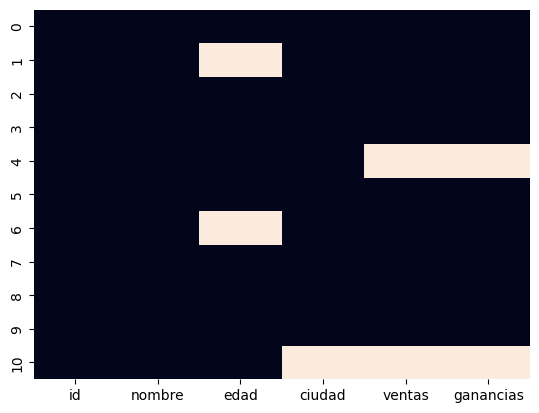

In [15]:
#Visualización:
sns.heatmap(df.isnull(), cbar=False)

7. Análisis de variables categóricas



In [18]:
#Contar categorías:
print(df["ciudad"].value_counts())

#Aqui es apreciable como hay valores equivalentes,
#pero como la grafia es distinta se ponen como valores diferentes

ciudad
Mexico         2
mexico         1
Guadalajara    1
MEXICO         1
guadalajara    1
colima         1
monterrey      1
Colima         1
sayula         1
Name: count, dtype: int64


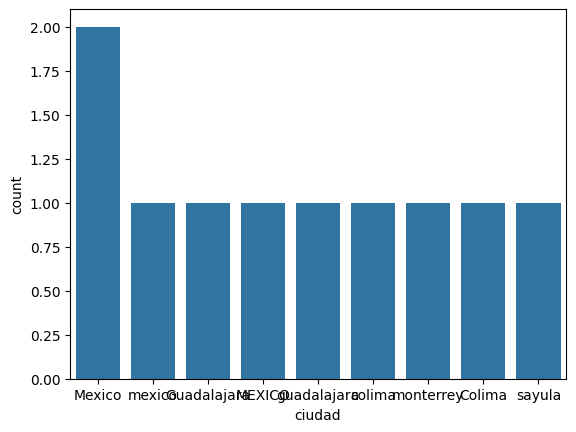

In [17]:
#Ejemplo gráfico:
sns.countplot(x="ciudad", data=df)
plt.show()

8. Distribución de variables numéricas

Esto muestra:

•	distribución
•	sesgo
•	outliers


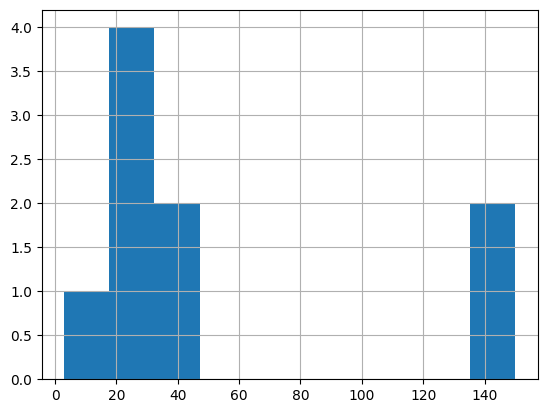

In [19]:
#Histograma:
df["edad"].hist()
plt.show()


<Axes: xlabel='edad', ylabel='Count'>

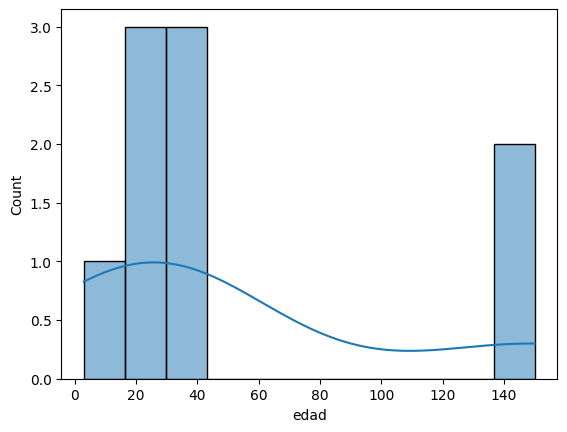

In [20]:
#Con seaborn:
sns.histplot(df["edad"], kde=True)
#creo que es mas estetico

9. Detección de outliers

Los outliers aparecen como puntos aislados.


<Axes: xlabel='edad'>

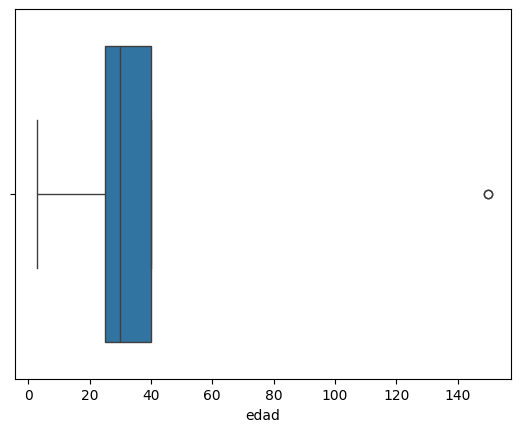

In [21]:
#Boxplot:
sns.boxplot(x=df["edad"])

10. Relación entre variables
Variables numéricas



In [24]:
#Matriz de correlación:
corr = df[["edad","ventas"]].corr()

print(corr)

            edad    ventas
edad    1.000000  0.333206
ventas  0.333206  1.000000


<Axes: >

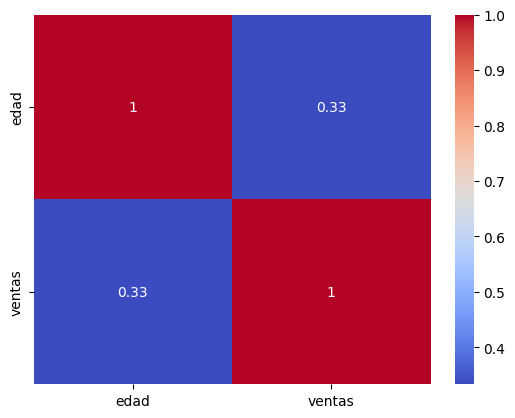

In [25]:
sns.heatmap(corr, annot=True, cmap="coolwarm")
#Esto muestra qué variables están relacionadas.

<Axes: xlabel='nombre', ylabel='edad'>

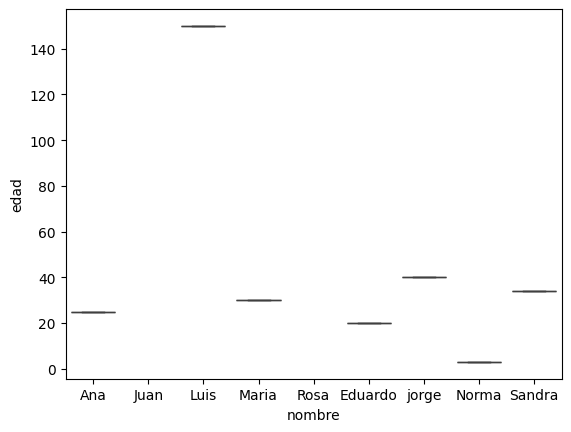

In [26]:
#Variables categóricas vs numéricas

sns.boxplot(x="nombre", y="edad", data=df)


11. Relaciones entre múltiples variables


•	patrones
•	clusters
•	tendencias

<Axes: xlabel='edad', ylabel='ventas'>

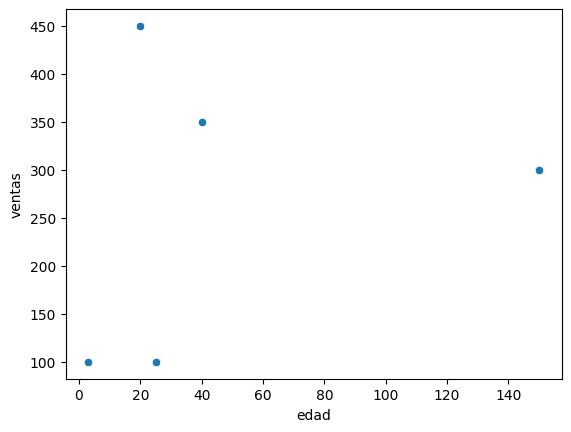

In [27]:
#Gráfico de dispersión:
sns.scatterplot(x="edad", y="ventas", data=df)
#Esto ayuda a detectar:

12. Agrupaciones con pandas


Ejemplo:
•	promedio de salario por género
•	ventas promedio por categoría


In [28]:
#Análisis por grupo:
df.groupby("ciudad")["ventas"].mean()

,ventas
ciudad,
Colima,350.0
Guadalajara,300.0
MEXICO,NaN
Mexico,100.0
colima,100000.0
guadalajara,300.0
mexico,200.0
monterrey,450.0
sayula,100.0


13. Análisis multivariable


Esto muestra relaciones entre todas las variables numéricas.


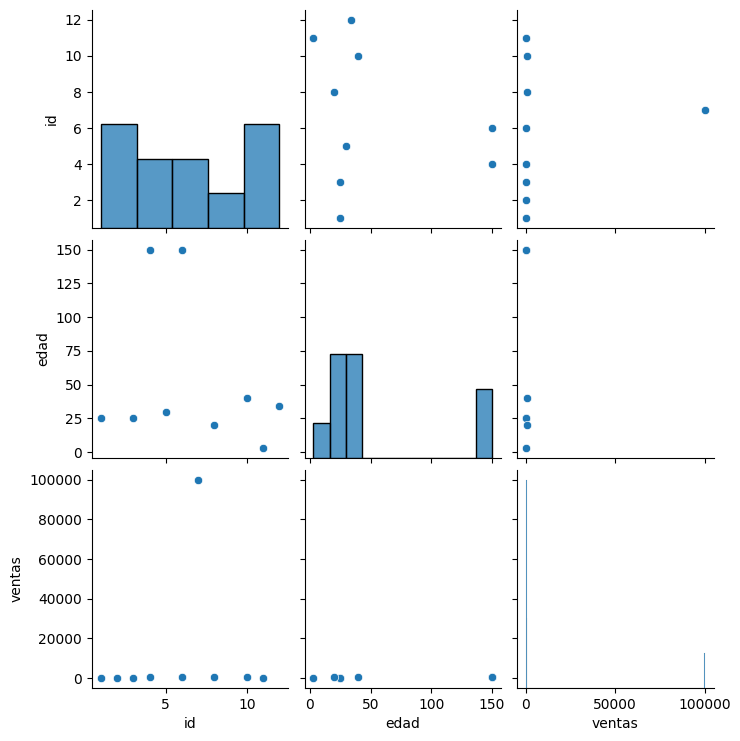

In [29]:
#Pairplot:
sns.pairplot(df)